# 06 -- Linear models (logistic regression)

Baseline PD model and scorecard backbone. Logistic regression is
interpretable and the natural reference every other family must beat.

This notebook:
1. Tunes regularisation strength, penalty, and class weighting with
   `GridSearchCV` over the saved stratified folds.
2. Shows validation and learning curves (bias/variance).
3. Plots an epoch-wise train/validation **loss curve** (log loss).
4. Evaluates the selected model once on the untouched holdout.

All preprocessing (impute/cap/missing-flags) is refit inside every CV
fold via `src.modeling.make_pipeline`, so there is no leakage.

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.modeling import (
    classification_metrics,
    cv_results_frame,
    evaluate_split,
    load_modeling_data,
    make_pipeline,
    metrics_frame,
    run_grid_search,
    subsample,
    train_valid_report,
)
from src.modeling import plots

data = load_modeling_data()
pd.Series(data.summary())


n_train                246005.0000
n_holdout               61502.0000
n_features                 52.0000
train_target_rate           0.0807
holdout_target_rate         0.0807
n_folds                     5.0000
pos_weight                 11.3900
dtype: float64

In [2]:
# Tune on a 20% stratified search sample (fast), then refit the chosen
# config on the FULL training partition below. Raise toward 1.0 for an
# exhaustive search. The holdout is never touched during tuning.
SEARCH_FRAC = 0.2
search = subsample(data, frac=SEARCH_FRAC)
pd.Series(search.summary())


n_train                49201.0000
n_holdout              61502.0000
n_features                52.0000
train_target_rate          0.0807
holdout_target_rate        0.0807
n_folds                    5.0000
pos_weight                11.3900
dtype: float64

## Hyperparameter search

Grid over `C`, `penalty`, and `class_weight`. AUC drives selection.

In [3]:
from sklearn.linear_model import LogisticRegression

# l2 + liblinear is the fast, standard scorecard setup. l1 (sparse) is
# available too but much slower on liblinear; add "l1" to penalty if you
# want feature selection and can wait.
logreg = LogisticRegression(max_iter=1000, solver="liblinear")
param_grid = {
    "C": [0.01, 0.1, 1.0, 3.0],
    "penalty": ["l2"],
    "class_weight": [None, "balanced"],
}
gs = run_grid_search(logreg, param_grid, search, refit="roc_auc")
cv_results_frame(gs).head(10)


Fitting 8 candidate(s) x 5 folds ...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Done in 208.9s. Best roc_auc=0.7271
Best params: {'model__C': 1.0, 'model__class_weight': 'balanced', 'model__penalty': 'l2'}


,param_model__C,param_model__class_weight,param_model__penalty,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,1.00,balanced,l2,0.730652,0.727067,0.026862,1
1,3.00,balanced,l2,0.729928,0.726632,0.020138,2
2,0.10,balanced,l2,0.716862,0.714744,0.024752,3
3,0.01,balanced,l2,0.714150,0.710715,0.011160,4
4,1.00,None,l2,0.593669,0.592481,0.016758,5
5,0.01,None,l2,0.585817,0.584371,0.007881,6
6,0.10,None,l2,0.586223,0.584234,0.008125,7
7,3.00,None,l2,0.584898,0.583952,0.006686,8


## Refit the selected model on the full training data

Selection used the search sample; the final model is trained on all 246k training rows for honest holdout evaluation and coefficients.

In [4]:
from sklearn.linear_model import LogisticRegression

best_params = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
print("selected:", best_params)
final_model = make_pipeline(LogisticRegression(max_iter=1000, solver="liblinear", **best_params))
final_model.fit(data.X_train, data.y_train)


selected: {'C': 1.0, 'class_weight': 'balanced', 'penalty': 'l2'}


,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('missing_flags', ...), ('impute', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,columns,"['app_ext_source_1', 'app_ext_source_2', ...]"
,lower,0.01
,upper,0.99


## Validation and learning curves

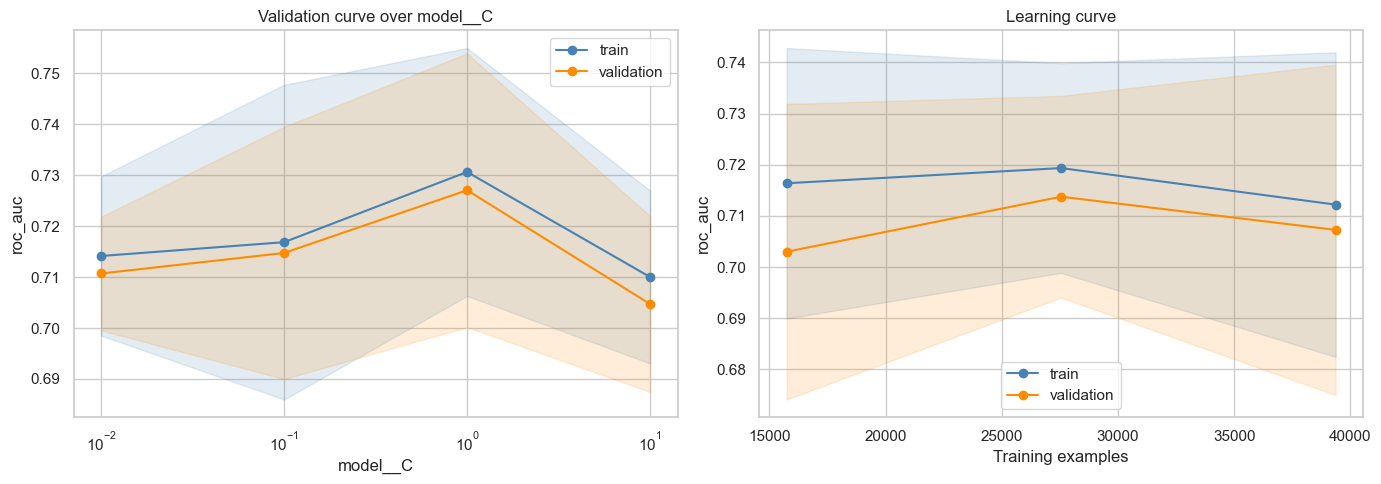

In [5]:
from sklearn.linear_model import LogisticRegression

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plots.plot_validation_curve(
    make_pipeline(LogisticRegression(max_iter=1000, solver="liblinear", class_weight="balanced")),
    search.X_train, search.y_train,
    param_name="model__C",
    param_range=[0.01, 0.1, 1.0, 10.0],
    cv=search.cv, semilog=True, ax=axes[0],
)
plots.plot_learning_curve(gs.best_estimator_, search.X_train, search.y_train, cv=search.cv, ax=axes[1], train_sizes=np.linspace(0.4, 1.0, 3))
plt.tight_layout()
plt.show()


## Loss curve (train vs validation)

Logistic regression has no native iteration history, so we fit an
equivalent log-loss SGD model incrementally and record log loss per epoch.

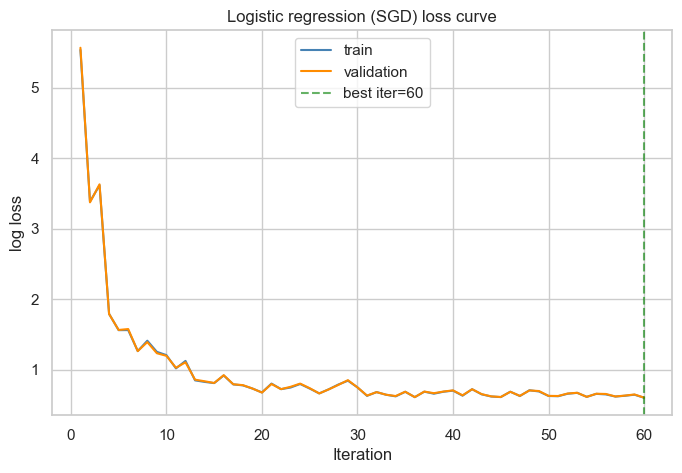

In [6]:
from src.modeling.linear import fit_logreg_sgd_curve

lc = fit_logreg_sgd_curve(
    search.X_train, search.y_train, data.X_holdout, data.y_holdout, n_epochs=60
)
plots.plot_loss_curve(lc.train_loss, lc.valid_loss, title="Logistic regression (SGD) loss curve")
plt.show()

## Holdout evaluation

In [7]:
# Train vs holdout metrics for the selected model (overfitting check)
report = train_valid_report(final_model, data, valid_as_holdout=True)
report.round(4)


,roc_auc,gini,ks,pr_auc,log_loss,brier,best_f1,best_f1_threshold
train,0.7115,0.4231,0.3142,0.1825,0.6236,0.2168,0.2576,0.6
holdout,0.7128,0.4256,0.3148,0.1859,0.6247,0.2174,0.2584,0.6


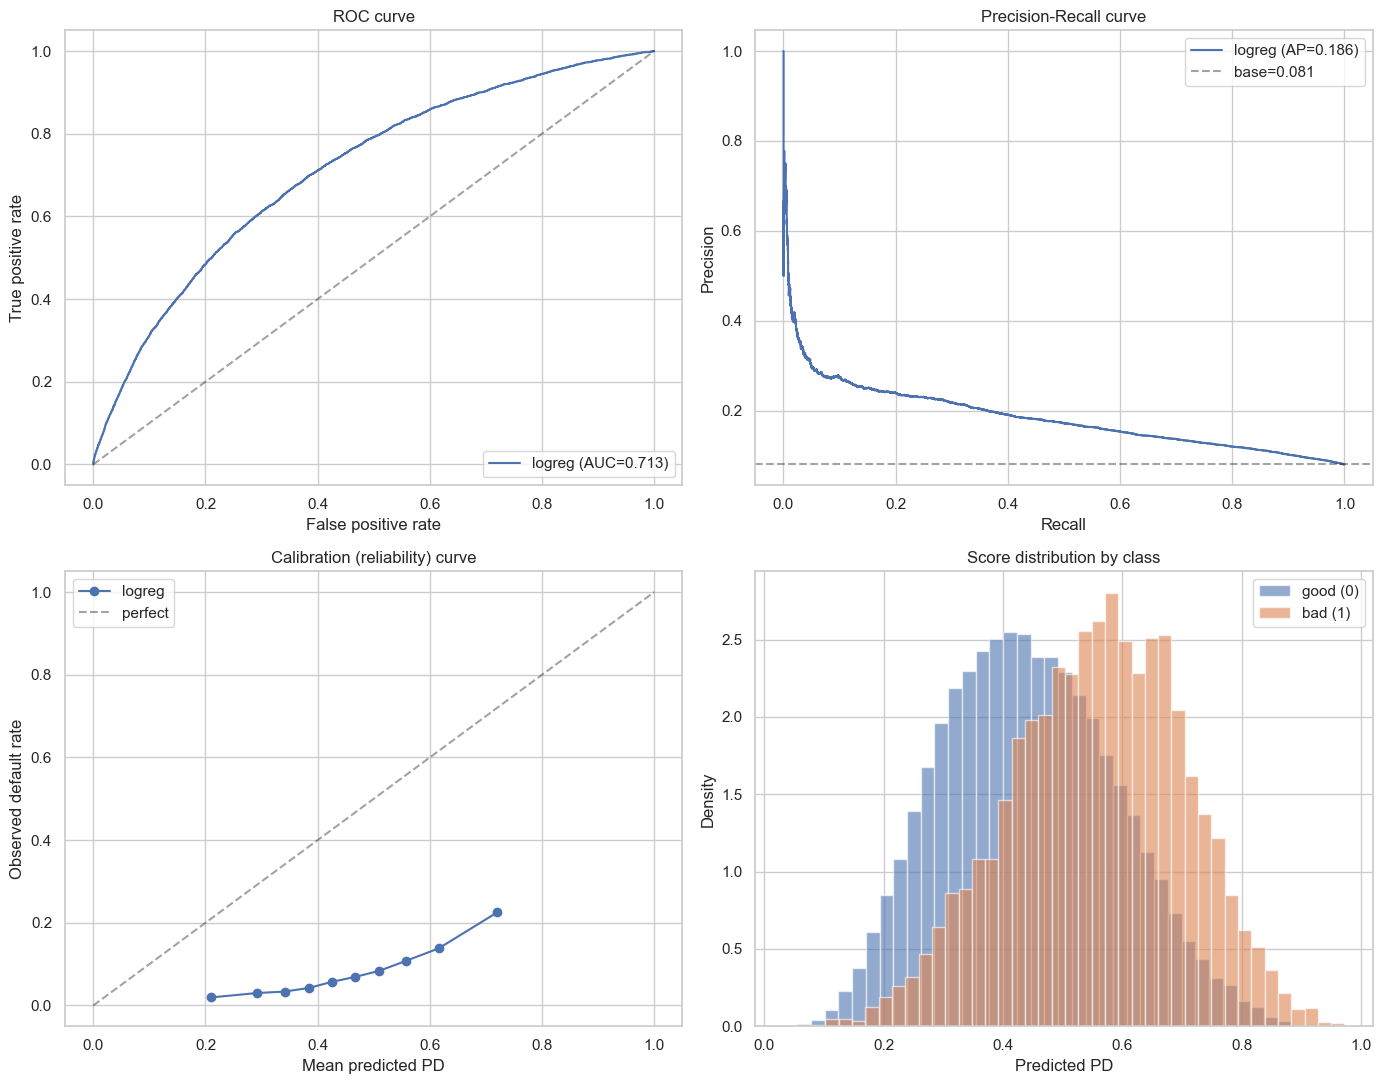

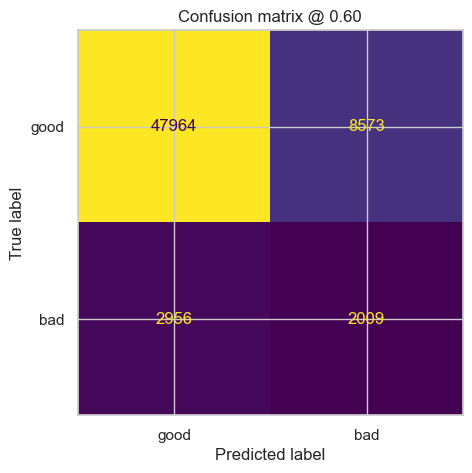

In [8]:
# Holdout diagnostics for the selected model
best = final_model
proba_ho = best.predict_proba(data.X_holdout)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plots.plot_roc_pr(data.y_holdout.to_numpy(), proba_ho, label="logreg", axes=axes[0])
plots.plot_calibration(data.y_holdout.to_numpy(), proba_ho, ax=axes[1][0], label="logreg")
plots.plot_score_distribution(data.y_holdout.to_numpy(), proba_ho, ax=axes[1][1])
plt.tight_layout()
plt.show()

best_t = classification_metrics(data.y_holdout.to_numpy(), proba_ho)["best_f1_threshold"]
fig, ax = plt.subplots(figsize=(5, 5))
plots.plot_confusion(data.y_holdout.to_numpy(), proba_ho, threshold=best_t, ax=ax)
plt.show()


## Coefficients

Standardised-scale coefficients ranked by absolute weight.

In [9]:
pre = final_model.named_steps["preprocess"]
feat_names = list(pre.transform(search.X_train.iloc[:1]).columns)
coef = pd.Series(final_model.named_steps["model"].coef_[0], index=feat_names)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(20).to_frame("coef")


,coef
app_ext_source_2,-0.467676
app_ext_source_3,-0.280908
app_credit_to_goods,0.233909
bur_utilisation,0.231013
app_ext_source_1_was_missing,0.224413
bur_utilisation_was_missing,0.187681
cc_utilisation_max,0.183393
app_ext_source_3_was_missing,0.173609
prev_credit_to_application_mean,0.167744
app_ext_source_1,-0.156748


## Takeaways

- Logistic regression gives the interpretable baseline AUC/KS on holdout.
- `class_weight="balanced"` compensates for the ~8% default rate.
- The gap between train and validation curves shows regularisation is
  controlling variance.
- Next families (trees, ensembles, boosting) are judged against this.